# 10 · Los huecos reales de la profundidad en NYUv2

Prueba 3 de la propuesta RGB-D (`proposal/PROPUESTA_RGBD_MLCA.md`). La condición «huecos reales» de la evaluación usa
`rawDepths`, la profundidad del Kinect antes de rellenar. Este notebook la describe antes de entrenar nada:

1. Que el cargador (`src/nyuv2.py`) lee bien el .mat: splits, formas, unidades y clases.
2. Cuánta profundidad falta, dónde cae en la imagen y en qué clases.
3. Cómo se ven esos huecos a las escalas de los rasgos (1/8, 1/16, 1/32), que es donde actúa la máscara del MLCA.
4. Cuánto afecta el canal min-max de DeFM con huecos reales (la trampa de `09_mlca_bloque`, §2.1).

No es una ablación: describe los datos y no lleva predicción previa. Uso de IA: notebook y cargador escritos con
asistencia de IA (Claude, Anthropic); ver `DECISIONES.md`.

In [ ]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
import nyuv2
from nyuv2 import NYUv2, EIGEN, clases40

FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)
NOMBRES = clases40()
ent, test = NYUv2("entrenamiento"), NYUv2("test")
print(f"entrenamiento {len(ent)} · test {len(test)} · comunes {len(set(ent.idx) & set(test.idx))}")
print(f"clases: {len(NOMBRES) - 1} + sin etiqueta ->", NOMBRES[1:6], "...", NOMBRES[-3:])

entrenamiento 795 · test 654 · comunes 0
clases: 40 + sin etiqueta -> ['wall', 'floor', 'cabinet', 'bed', 'chair'] ... ['otherstructure', 'otherfurniture', 'otherprop']


## 1. El cargador

In [ ]:
s = test[0]
for k, v in s.items():
    if isinstance(v, np.ndarray):
        print(f"{k:12s} {str(v.shape):15s} {str(v.dtype):8s} [{v.min():.3g}, {v.max():.3g}]")
cr, pr = s["cruda"], s["profundidad"]
v = cr > 0
print(f"\nhuecos en la cruda: {(~v).mean():.1%} · donde hay medida, |rellenada - cruda| "
      f"máx. {np.abs(pr[v] - cr[v]).max():.3g} m, mediana {np.median(np.abs(pr[v] - cr[v])):.3g} m")
print("rellenada sin ceros:", bool((pr > 0).all()))

rgb          (480, 640, 3)   uint8    [0, 255]
profundidad  (480, 640)      float32  [1.8, 3.62]
cruda        (480, 640)      float32  [0, 3.64]
etiqueta     (480, 640)      uint8    [0, 40]

huecos en la cruda: 23.9% · donde hay medida, |rellenada - cruda| máx. 0.293 m, mediana 0.00154 m
rellenada sin ceros: True


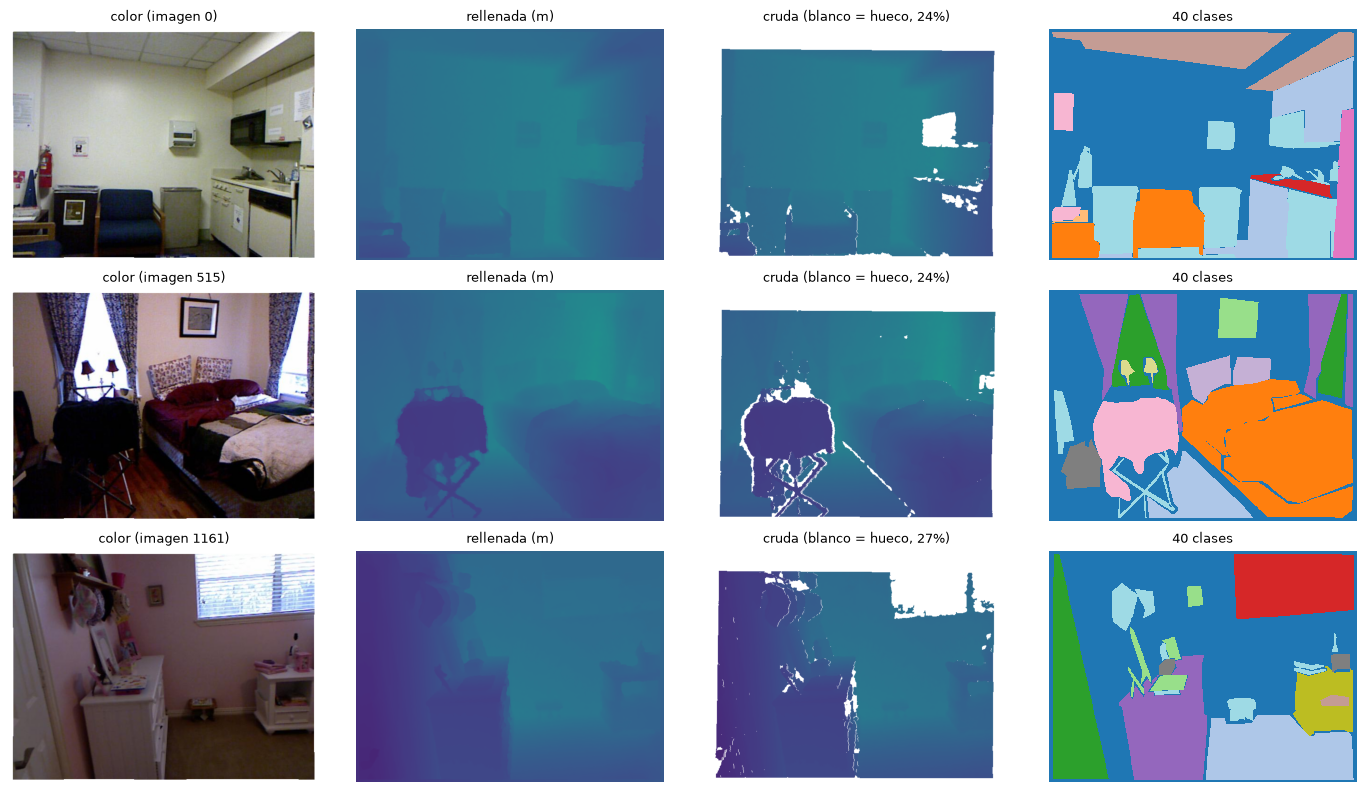

In [ ]:
fig, ax = plt.subplots(3, 4, figsize=(14, 8))
for fila, i in enumerate([0, 200, 500]):
    s = test[i]
    ax[fila, 0].imshow(s["rgb"]); ax[fila, 0].set_title(f"color (imagen {s['indice']})", fontsize=9)
    ax[fila, 1].imshow(s["profundidad"], cmap="viridis", vmin=0, vmax=8); ax[fila, 1].set_title("rellenada (m)", fontsize=9)
    cr = np.ma.masked_where(s["cruda"] == 0, s["cruda"])
    ax[fila, 2].imshow(np.zeros_like(s["cruda"]), cmap="gray_r", vmin=0, vmax=1)
    ax[fila, 2].imshow(cr, cmap="viridis", vmin=0, vmax=8)
    ax[fila, 2].set_title(f"cruda (blanco = hueco, {(s['cruda'] == 0).mean():.0%})", fontsize=9)
    ax[fila, 3].imshow(s["etiqueta"], cmap="tab20", vmin=0, vmax=40, interpolation="nearest")
    ax[fila, 3].set_title("40 clases", fontsize=9)
for a in ax.flat: a.axis("off")
fig.tight_layout(); fig.savefig(FIGS / "10_1_ejemplos.png", dpi=110); plt.show()

## 2. Cuánta profundidad falta, dónde y en qué clases

Una pasada por las 1 449 imágenes. La fracción de huecos se da en la imagen completa y dentro del recorte de
Eigen (sin el borde blanco del registro). A las escalas de los rasgos, cada celda tiene una fracción válida
m ∈ [0, 1] (promedio por áreas, como `validez_a_rasgos`); solo las celdas con m = 0 salen del todo del resumen.

In [ ]:
ESCALAS = (8, 16, 32)
def recorrer(ds):
    r = {"completa": [], "eigen": [], "mapa": np.zeros((480, 640)), "hueco_clase": np.zeros(41), "px_clase": np.zeros(41),
         "min_valida": [], **{f"vacias_{e}": [] for e in ESCALAS}, **{f"parciales_{e}": [] for e in ESCALAS},
         "prof_hueco": [], "prof_valida": []}
    rng = np.random.default_rng(0)
    for i in range(len(ds)):
        s = ds[i]; h = s["cruda"] == 0; et = s["etiqueta"]
        r["completa"].append(h.mean()); r["eigen"].append(h[EIGEN].mean()); r["mapa"] += h
        r["hueco_clase"] += np.bincount(et[h], minlength=41); r["px_clase"] += np.bincount(et.ravel(), minlength=41)
        r["min_valida"].append(s["cruda"][~h].min())
        for e in ESCALAS:
            m = (~h).reshape(480 // e, e, 640 // e, e).mean((1, 3))
            r[f"vacias_{e}"].append((m == 0).mean()); r[f"parciales_{e}"].append(((m > 0) & (m < 1)).mean())
        sel = rng.random(h.shape) < 0.01                                   # 1 % de los píxeles, para el histograma
        r["prof_hueco"].append(s["profundidad"][h & sel]); r["prof_valida"].append(s["profundidad"][~h & sel])
    r["mapa"] /= len(ds)
    for k in ("prof_hueco", "prof_valida"):
        r[k] = np.concatenate(r[k])
    return {k: (np.array(v) if isinstance(v, list) else v) for k, v in r.items()}

R = {"entrenamiento": recorrer(ent), "test": recorrer(test)}
for n, r in R.items():
    for zona in ("completa", "eigen"):
        x = r[zona]
        print(f"{n:13s} {zona:8s}: media {x.mean():.1%}  mediana {np.median(x):.1%}  p90 {np.percentile(x, 90):.1%}  "
              f"máx. {x.max():.1%}  · imágenes sin huecos {(x == 0).mean():.1%}")

entrenamiento completa: media 32.0%  mediana 30.1%  p90 43.6%  máx. 85.1%  · imágenes sin huecos 0.0%
entrenamiento eigen   : media 13.9%  mediana 11.5%  p90 28.5%  máx. 81.2%  · imágenes sin huecos 0.0%
test          completa: media 30.7%  mediana 28.6%  p90 41.8%  máx. 68.6%  · imágenes sin huecos 0.0%
test          eigen   : media 12.3%  mediana 9.6%  p90 26.4%  máx. 60.7%  · imágenes sin huecos 0.0%


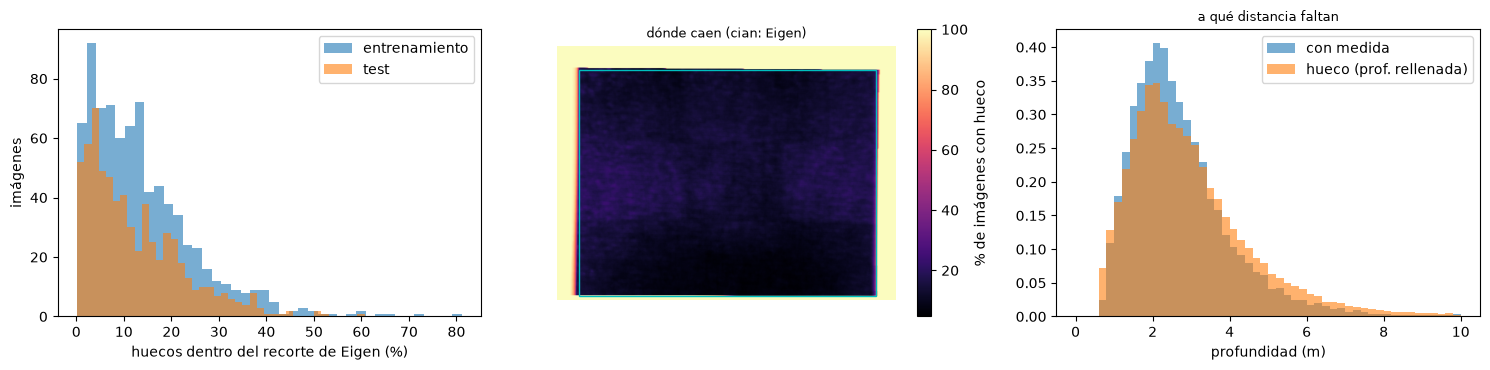

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for n, r in R.items():
    ax[0].hist(100 * r["eigen"], bins=40, alpha=0.6, label=n)
ax[0].set_xlabel("huecos dentro del recorte de Eigen (%)"); ax[0].set_ylabel("imágenes"); ax[0].legend()
mapa = (len(ent) * R["entrenamiento"]["mapa"] + len(test) * R["test"]["mapa"]) / (len(ent) + len(test))
im = ax[1].imshow(100 * mapa, cmap="magma"); plt.colorbar(im, ax=ax[1], label="% de imágenes con hueco")
ax[1].add_patch(plt.Rectangle((41, 45), 560, 426, fill=False, ec="c", lw=1)); ax[1].set_title("dónde caen (cian: Eigen)", fontsize=9)
ax[1].axis("off")
b = np.linspace(0, 10, 51)
for k, lab in [("prof_valida", "con medida"), ("prof_hueco", "hueco (prof. rellenada)")]:
    x = np.concatenate([R["entrenamiento"][k], R["test"][k]])
    ax[2].hist(x, bins=b, density=True, alpha=0.6, label=lab)
ax[2].set_xlabel("profundidad (m)"); ax[2].legend(); ax[2].set_title("a qué distancia faltan", fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "10_2_huecos.png", dpi=120); plt.show()

La profundidad en los huecos es la **rellenada**, no una medida: el histograma de la derecha es indicativo.

clases con más profundidad ausente (todas las imágenes):
  window              65.0% de sus píxeles  ·   2.1% de la imagen
  ceiling             59.9% de sus píxeles  ·   1.4% de la imagen
  mirror              55.4% de sus píxeles  ·   1.0% de la imagen
  television          51.0% de sus píxeles  ·   0.5% de la imagen
  otherstructure      43.6% de sus píxeles  ·   2.0% de la imagen
  refridgerator       38.8% de sus píxeles  ·   0.6% de la imagen
  lamp                36.1% de sus píxeles  ·   0.3% de la imagen
  door                34.5% de sus píxeles  ·   2.2% de la imagen
  counter             32.9% de sus píxeles  ·   1.4% de la imagen
  table               30.6% de sus píxeles  ·   2.1% de la imagen
  shower curtain      30.3% de sus píxeles  ·   0.4% de la imagen
  blinds              29.8% de sus píxeles  ·   1.7% de la imagen
…
  floor mat           12.4%
  bed                 12.1%
  bathtub             11.8%
  toilet              10.2%
  pillow               9.7%

«sin eti

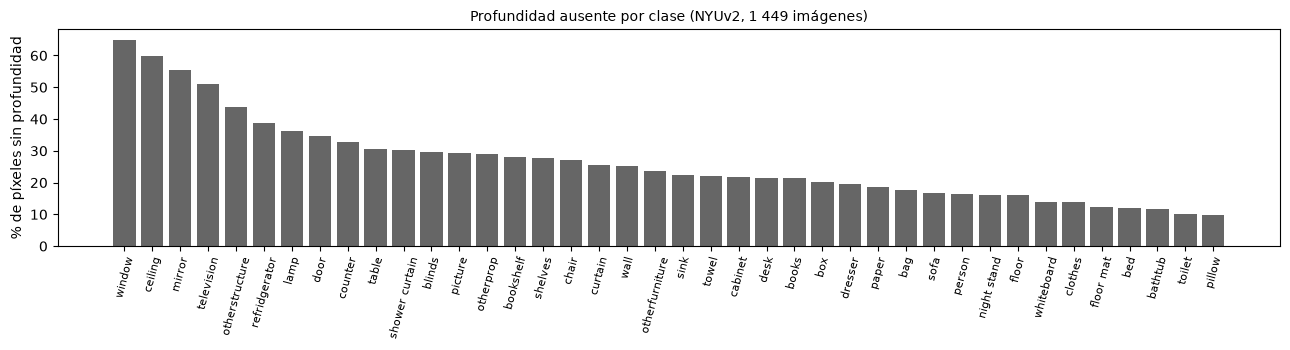

In [ ]:
hc = R["entrenamiento"]["hueco_clase"] + R["test"]["hueco_clase"]
pc = R["entrenamiento"]["px_clase"] + R["test"]["px_clase"]
frac = hc / np.maximum(pc, 1)
orden = np.argsort(-frac[1:]) + 1
print("clases con más profundidad ausente (todas las imágenes):")
for c in orden[:12]:
    print(f"  {NOMBRES[c]:18s} {frac[c]:6.1%} de sus píxeles  ·  {pc[c] / pc.sum():5.1%} de la imagen")
print("…")
for c in orden[-5:]:
    print(f"  {NOMBRES[c]:18s} {frac[c]:6.1%}")
print(f"\n«sin etiqueta»: {frac[0]:.1%} de sus píxeles son hueco ({hc[0] / hc.sum():.0%} de todos los huecos)")

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(range(40), 100 * frac[orden], color="0.4")
ax.set_xticks(range(40)); ax.set_xticklabels([NOMBRES[c] for c in orden], rotation=75, fontsize=8)
ax.set_ylabel("% de píxeles sin profundidad"); ax.set_title("Profundidad ausente por clase (NYUv2, 1 449 imágenes)", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "10_3_por_clase.png", dpi=120); plt.show()

## 3. Los huecos a la escala de los rasgos

Una celda **vacía** (m = 0) sale del resumen; una **parcial** (0 < m < 1) entra con su peso. Cuanto más gruesa la
escala, menos celdas vacías: a 1/32 la máscara casi solo pondera.

In [ ]:
print(f"{'escala':>7} {'celdas':>7} {'vacías (test)':>14} {'parciales (test)':>17} {'imágenes con alguna vacía':>27}")
for e in ESCALAS:
    va, pa = R["test"][f"vacias_{e}"], R["test"][f"parciales_{e}"]
    print(f"  1/{e:<4} {(480 // e) * (640 // e):7d} {va.mean():13.1%} {pa.mean():16.1%} {(va > 0).mean():26.1%}")

 escala  celdas  vacías (test)  parciales (test)   imágenes con alguna vacía
  1/8       4800         24.6%            16.3%                     100.0%
  1/16      1200         19.2%            31.0%                     100.0%
  1/32       300         17.1%            50.0%                     100.0%


## 4. El canal min-max de DeFM con huecos reales

`convert_to_3channel_metric` toma el mínimo de cada imagen **incluyendo los ceros de los huecos**. Si hay al menos
un hueco, el mínimo pasa a ser 0 en vez de la profundidad válida más cercana, y el canal 3 de todos los píxeles
válidos se recodifica.

In [ ]:
mv = np.concatenate([R["entrenamiento"]["min_valida"], R["test"]["min_valida"]])
con_hueco = np.concatenate([R["entrenamiento"]["completa"], R["test"]["completa"]]) > 0
print(f"imágenes con al menos un hueco: {con_hueco.mean():.1%}")
print(f"profundidad válida mínima en esas imágenes: mediana {np.median(mv[con_hueco]):.2f} m, "
      f"p10 {np.percentile(mv[con_hueco], 10):.2f} m, p90 {np.percentile(mv[con_hueco], 90):.2f} m")

import torch
sys.path.insert(0, str(Path(torch.hub.get_dir()) / "leggedrobotics_defm_main"))   # descargado en 09_mlca_bloque
from defm.utils.utils import convert_to_3channel_metric
cambio = []
for i in range(0, len(test), 10):                                        # una de cada diez del test
    s = test[i]; h = s["cruda"] == 0
    if not h.any():
        continue
    a = convert_to_3channel_metric(s["cruda"])[..., 2]                   # oficial: mínimo con los ceros
    cr = s["cruda"].copy(); cr[h] = s["cruda"][~h].min()                 # mínimo solo sobre los válidos
    b = convert_to_3channel_metric(cr)[..., 2]
    cambio.append(np.abs(a - b)[~h].mean())
print(f"cambio medio del canal 3 en píxeles válidos ({len(cambio)} imágenes de test): "
      f"mediana {np.median(cambio):.3f}, p90 {np.percentile(cambio, 90):.3f}  (el canal va de 0 a 1)")

imágenes con al menos un hueco: 100.0%
profundidad válida mínima en esas imágenes: mediana 1.11 m, p10 0.71 m, p90 1.72 m


cambio medio del canal 3 en píxeles válidos (66 imágenes de test): mediana 0.206, p90 0.315  (el canal va de 0 a 1)


## 5. Resumen

Las cifras de arriba son la fuente. La condición «huecos reales» de la propuesta queda descrita; las condiciones
sintéticas (huecos aleatorios, regiones contiguas) se pueden calibrar con el §2 y el §3.

> ✍️ **Lectura del equipo:** (pendiente)